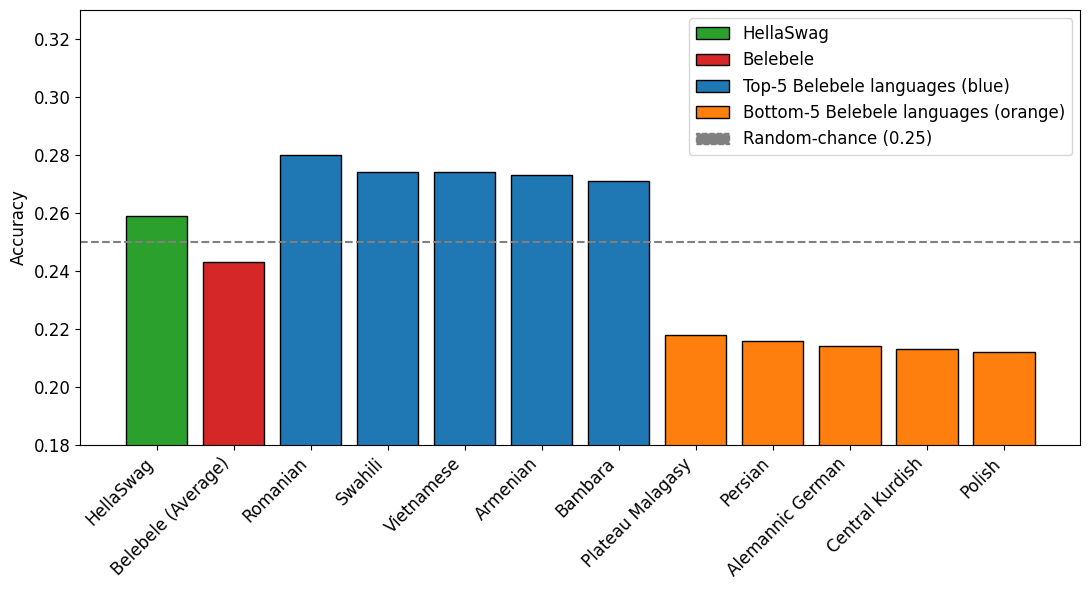

In [1]:
# --------------------------------------------------------------
# Imports
# --------------------------------------------------------------
import matplotlib.pyplot as plt
from matplotlib.patches import Patch   # for a custom legend

# --------------------------------------------------------------
# Data (kept in the original order)
# --------------------------------------------------------------
data = {
    "HellaSwag": 0.259,
    "Belebele (Average)":      0.243,
    "Romanian":                0.280,
    "Swahili":                 0.274,
    "Vietnamese":              0.274,
    "Armenian":                0.273,
    "Bambara":                 0.271,
    "Plateau Malagasy":        0.218,
    "Persian":                 0.216,
    "Alemannic German":        0.214,
    "Central Kurdish":         0.213,
    "Polish":                  0.212
}

# --------------------------------------------------------------
# Colour assignment
# --------------------------------------------------------------
#  – group‑1 languages
group1 = {"Romanian", "Swahili", "Vietnamese", "Armenian", "Bambara"}
#  – group‑2 languages
group2 = {"Plateau Malagasy", "Persian", "Alemannic German", "Central Kurdish", "Polish"}

col_group1 = "#1f77b4"   # blue
col_group2 = "#ff7f0e"   # orange
col_hellaswag = "#2ca02c"   # green
col_belebele   = "#d62728"   # red

# Build a dict that maps every label to its colour
colour_map = {}
for label in data:
    if label == "HellaSwag":
        colour_map[label] = col_hellaswag
    elif label == "Belebele (Average)":
        colour_map[label] = col_belebele
    elif label in group1:
        colour_map[label] = col_group1
    elif label in group2:
        colour_map[label] = col_group2
    else:
        colour_map[label] = "gray"   # fallback – should never happen

# --------------------------------------------------------------
# Plotting
# --------------------------------------------------------------
labels  = list(data.keys())
values  = [data[l] for l in labels]
colours = [colour_map[l] for l in labels]

plt.figure(figsize=(11, 6))

bars = plt.bar(labels, values, color=colours, edgecolor="black")

# Dotted “random‑chance” line at 0.25
plt.axhline(
    0.25,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Random‑chance (0.25)"
)

# Tidy up the axes
plt.ylim(0.18, max(values) + 0.05)

# -------------------- BIGGER TEXT --------------------
plt.ylabel("Accuracy", fontsize=12)             # y‑axis label
plt.xticks(rotation=45, ha="right", fontsize=12)  # x‑tick labels
plt.yticks(fontsize=12)                         # y‑tick labels
# plt.title("Your title here", fontsize=18)    # optional title
# ----------------------------------------------------

# --------------------------------------------------------------
# Custom legend (also with larger font)
# --------------------------------------------------------------
legend_elements = [
    Patch(facecolor=col_hellaswag, edgecolor="black", label="HellaSwag"),
    Patch(facecolor=col_belebele,   edgecolor="black", label="Belebele"),
    Patch(facecolor=col_group1, edgecolor="black",
          label="Top‑5 Belebele languages (blue)"),
    Patch(facecolor=col_group2, edgecolor="black",
          label="Bottom‑5 Belebele languages (orange)"),
    Patch(facecolor="gray", edgecolor="gray", linestyle="--",
          label="Random‑chance (0.25)")
]

plt.legend(handles=legend_elements,
           loc="upper right",
           fontsize=12)           # legend text size


pdf_path = "model2_moe_perf.pdf"
plt.savefig(pdf_path, format="pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()

In [2]:
# -------------------------------------------------
# 1️⃣  Imports & original data
# -------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# -------------------------------------------------
# Choose a Matplotlib style (any name from plt.style.available)
# -------------------------------------------------
# Example list (run `print(plt.style.available)` in a console to see all):
# ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid',
#  'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot',
#  'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright',
#  'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette',
#  'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted',
#  'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel',
#  'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks',
#  'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']

STYLE = "seaborn-v0_8"          # <- change this to any style you like
plt.style.use(STYLE)

# -------------------------------------------------
# Nested dictionary you supplied
# -------------------------------------------------
data = {
    "Cyrillic": {
        "Khalkha": {"original": 0.328, "mistral": 0.270},
        "Kazakh":   {"original": 0.333, "mistral": 0.290},
    },
    "Georgian": {
        "Georgian": {"original": 0.323, "mistral": 0.210},
    },
    "Austronesian": {
        "Sundanese":    {"original": 0.451, "mistral": 0.27},
        "Javanese": {"original": 0.353, "mistral": 0.25},
    },
    "Arabic": {
        "Levantine": {"original": 0.360, "mistral": 0.30},
        "Egyptian":  {"original": 0.380, "mistral": 0.30},
        "Najdi":     {"original": 0.270, "mistral": 0.310},
        "MSA":      {"original": 0.380, "mistral": 0.305},
        "Mesopotamian":      {"original": 0.370, "mistral": 0.330},
    },
    "African": {
        "Swahili":  {"original": 0.290, "mistral": 0.260},
        "Zulu":     {"original": 0.315, "mistral": 0.23},
        "Sepedi":   {"original": 0.280, "mistral": 0.270},
        "Tswana":   {"original": 0.300, "mistral": 0.265},
        "Sotho":    {"original": 0.325, "mistral": 0.290},
        "Yoruba":   {"original": 0.250, "mistral": 0.210},
        "Igbo":     {"original": 0.270, "mistral": 0.260},
    }
}

In [3]:
# -------------------------------------------------
# 2️⃣  Flatten → DataFrame (one row per language)
# -------------------------------------------------
rows = []
for family, langs in data.items():
    for lang, scores in langs.items():
        rows.append({
            "family":   family,
            "language": lang,
            "original": scores["original"],
            "mistral":  scores["mistral"]
        })

df = pd.DataFrame(rows)
df

,family,language,original,mistral
0,Cyrillic,Khalkha,0.328,0.270
1,Cyrillic,Kazakh,0.333,0.290
2,Georgian,Georgian,0.323,0.210
3,Austronesian,Sundanese,0.451,0.270
4,Austronesian,Javanese,0.353,0.250
5,Arabic,Levantine,0.360,0.300
6,Arabic,Egyptian,0.380,0.300
7,Arabic,Najdi,0.270,0.310
8,Arabic,MSA,0.380,0.305
9,Arabic,Mesopotamian,0.370,0.330


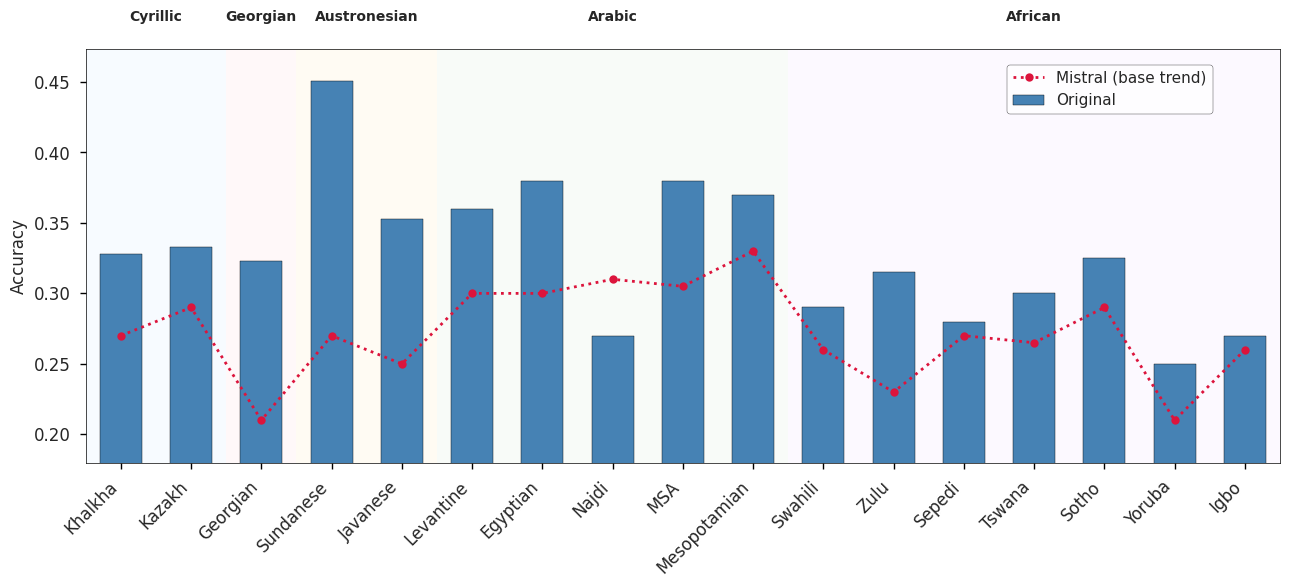

In [6]:
# -------------------------------------------------
# 3️⃣  Plotting (middle‑aligned group labels)
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6))

# -------------------------------------------------
# 1️⃣  X positions – one per language
# -------------------------------------------------
x_positions = np.arange(len(df))
tick_labels = df['language'].tolist()

# -------------------------------------------------
# 2️⃣  Determine start / end index of each family block
# -------------------------------------------------
family_spans = []
family_names = []
cur = 0
for fam, sub in df.groupby('family', sort=False):
    n = len(sub)
    family_spans.append((cur, cur + n - 1))
    family_names.append(fam)
    cur += n

# -------------------------------------------------
# 3️⃣  Light coloured background bands (same as before)
# -------------------------------------------------
FAMILY_COLORS = ["#cce5ff", "#ffd1dc", "#ffe5b4", "#d5e8d4", "#f0d9ff"]
ALPHA = 0.15
for i, (start, end) in enumerate(family_spans):
    ax.axvspan(start - 0.5, end + 0.5,
               facecolor=FAMILY_COLORS[i % len(FAMILY_COLORS)],
               alpha=ALPHA,
               edgecolor='none',
               linewidth=0,
               zorder=0)

# -------------------------------------------------
# 4️⃣  Bars – slightly wider for compact look
# -------------------------------------------------
bar_width = 0.6
orig_vals = df['original'].values
ax.bar(x_positions,
       orig_vals,
       width=bar_width,
       label='Original',
       color='steelblue',
       edgecolor='black',
       zorder=3)

# -------------------------------------------------
# 5️⃣  Dotted line through Mistral values
# -------------------------------------------------
mist_vals = df['mistral'].replace({None: np.nan}).astype(float).values
valid = ~np.isnan(mist_vals)
line_x = x_positions[valid]
line_y = mist_vals[valid]
ax.plot(line_x, line_y,
        color='crimson',
        linestyle=':',
        linewidth=2,
        marker='o',
        markersize=6,
        label='Mistral (base trend)',
        zorder=4)
# -------------------------------------------------
# 6️⃣  Family names (group labels) – perfectly centered ABOVE the plot
# -------------------------------------------------
# Compute midpoints for each family group
family_mid_positions = [(start + end) / 2 for start, end in family_spans]

# Place text in axes coordinates, not data coordinates
# y=1 is the top edge of the axes; 1.06 places text slightly above it
for fam, x_mid in zip(family_names, family_mid_positions):
    ax.text(x_mid, 1.06, fam,
            transform=ax.get_xaxis_transform(),  # ensures horizontal alignment with data space
            ha='center', va='bottom',
            fontsize=10, fontweight='bold')

# Add a bit of top margin so labels don’t get cut off
fig.subplots_adjust(top=0.88)

# -------------------------------------------------
# 7️⃣  Final cosmetics
# -------------------------------------------------
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)

ax.tick_params(axis='y', which='major', labelsize=12)

ax.set_xticks(x_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_ylim(bottom=0.18)
ax.set_title('', fontsize=14, pad=15)

ax.legend(fontsize=11,
          loc='upper right',
          bbox_to_anchor=(0.95, 0.98),
          frameon=True,
          facecolor='white',
          edgecolor='black')

# Styling spines
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(0.5)
ax.patch.set_visible(False)

ax.tick_params(which='both', direction='out', length=4, width=1, color='black')
ax.set_xlim(-0.5, len(df) - 0.5)

pdf_path = "adapters_vs_base_only.pdf"
plt.savefig(pdf_path, format="pdf", bbox_inches="tight")

fig.tight_layout()
plt.show()